# viability-brackets (R1) *(draft digest)*

> **Status:** DRAFT in `Research/_drafts/` — approval-gated (see `Research/README.md`).
> **2026-10-23:** switched to the standard-model rescan (`food_cap=1`); R1's recorded headline was produced by the
> legacy uncapped mouthful (defect A9) and is superseded (see "Recorded headline" at the end).

## Question

**Where are the productive optima in (`m_scale`, `food_inc`)?** #1 left both levers pinned at
their grid edges — R1 brackets them to test whether the optima are *interior* (real) or
*runaway* (grid artifacts).

## Method

`R1_mscale_bracket`: `m_scale ∈ {2.5, 3.5, 5.0}` (was ceiling-pinned at 2.5) ×
`food_inc ∈ {0.005 … 0.018}` (extended below #2's 0.010 low edge). Mirrors the #1 joint design
exactly (300 configs, 8000 ticks, N=256, one seed per config). Data: the 2026-10-23 standard-model rescan
`Scans/2026-10-23_R1_mscale_bracket_standard` (same driver and configs, `food_cap=1`, today's code, 0 errors).
Composite ranking as in R1's devlog: z-normalized sum over viable rows of `dyn_excess_pc_slope`,
`eg_excess_pc_slope`, `n_distinct_genomes_temporal_std`, `unique_top_genomes`.

## Headline result (standard model)

- **No interior `m_scale` optimum.** Composite top 20: `m_scale` 2.5 ×2, 3.5 ×9, 5.0 ×9. Median
  `eg_excess_pc_slope` rises monotonically (5.65, 10.87, 17.11) while `dyn_excess_pc_slope` is flat
  (11.05, 11.49, 10.08): the productive `m_scale` is at the grid's upper edge again.
- **Viability is not U-shaped.** Extinction 30/300 (10%): 13.5 / 8.3 / 8.4% at `m_scale` 2.5 / 3.5 / 5.0,
  confined to `food_inc` ≤ 0.010.
- **`food_inc`: high end leads per metric, low end not closed.** The top quartiles of `dyn_excess` and
  `eg_excess` hold 26 and 30 of 68 rows at `food_inc` 0.018, but the composite top 20 spans every level
  (0.005 ×1, 0.008 ×4, 0.010 ×3, 0.013 ×7, 0.018 ×5).
- **Low `mu_lut` wins**: composite top-20 mode 0.01 (8/20), as in #1.

In [1]:
# --- draft digest notebook: shared setup ---
# Locates the repo root (dir containing C/evoca.h) by walking up from CWD,
# so the notebook loads raw artifacts wherever it is executed from.
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

def repo_root():
    p = Path.cwd().resolve()
    for cand in [p, *p.parents]:
        if (cand / "C" / "evoca.h").is_file():
            return cand
    raise FileNotFoundError("could not locate repo root (no C/evoca.h above CWD)")

ROOT = repo_root()
print("repo root:", ROOT)


repo root: /private/tmp/evoca_food-cap-standard


In [2]:
r1 = pd.read_csv(ROOT / "Research/Resource-driving/Scans/2026-10-23_R1_mscale_bracket_standard/results.csv")
print(f"{len(r1)} rows, extinct={int(r1.extinct.sum())} ({r1.extinct.mean()*100:.0f}%)")
print("m_scale levels:", sorted(r1.param_m_scale.unique()))
print("food_inc levels:", sorted(r1.param_food_inc.unique()))


300 rows, extinct=30 (10%)
m_scale levels: [np.float64(2.5), np.float64(3.5), np.float64(5.0)]
food_inc levels: [np.float64(0.005), np.float64(0.008), np.float64(0.01), np.float64(0.013), np.float64(0.018)]


### Viability in `m_scale` (not U-shaped) and extinction by food scarcity

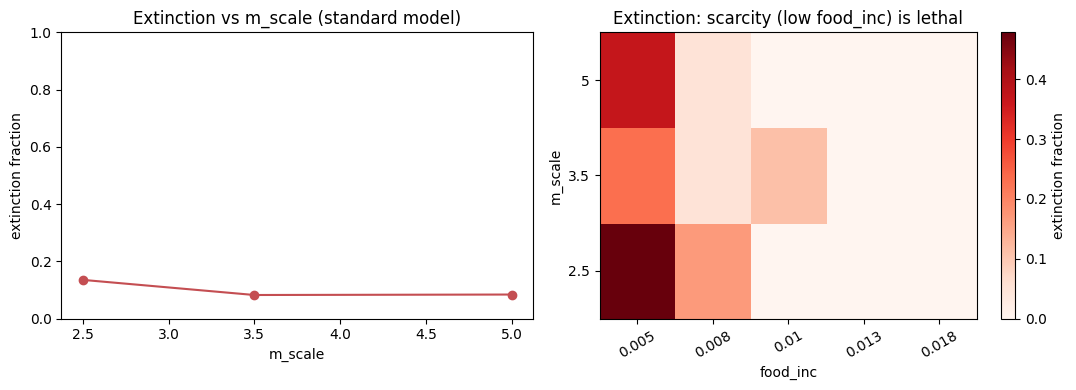

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# (a) extinction vs m_scale
ext = r1.groupby("param_m_scale").extinct.mean()
axes[0].plot(ext.index, ext.values, "o-", color="#C44E52")
axes[0].set_xlabel("m_scale"); axes[0].set_ylabel("extinction fraction")
axes[0].set_title("Extinction vs m_scale (standard model)"); axes[0].set_ylim(0, 1)

# (b) extinction heatmap over (m_scale, food_inc)
piv = r1.groupby(["param_m_scale", "param_food_inc"]).extinct.mean().unstack()
im = axes[1].imshow(piv.values, aspect="auto", origin="lower", cmap="Reds")
axes[1].set_xticks(range(len(piv.columns))); axes[1].set_xticklabels([f"{c:g}" for c in piv.columns], rotation=30)
axes[1].set_yticks(range(len(piv.index)));   axes[1].set_yticklabels([f"{r:g}" for r in piv.index])
axes[1].set_xlabel("food_inc"); axes[1].set_ylabel("m_scale")
axes[1].set_title("Extinction: scarcity (low food_inc) is lethal")
fig.colorbar(im, ax=axes[1], label="extinction fraction")
fig.tight_layout(); plt.show()


### Where the productive (high-excess) configs sit

Composite top 20, and the top quartile of each excess metric, over viable rows.

composite top-20 param_m_scale: {2.5: 2, 3.5: 9, 5.0: 9}
composite top-20 param_food_inc: {0.005: 1, 0.008: 4, 0.01: 3, 0.013: 7, 0.018: 5}
composite top-20 param_mu_lut: {0.01: 8, 0.03: 4, 0.06: 2, 0.1: 2, 0.15: 4}
composite top-20 param_tax: {0.03: 18, 0.035: 2}

medians over viable rows by m_scale:
               dyn_excess_pc_slope  eg_excess_pc_slope  cog_specificity_mean
param_m_scale                                                               
2.5                          11.05                5.65                 13.74
3.5                          11.49               10.87                 13.31
5.0                          10.08               17.11                  8.61

top-quartile dyn_excess_pc_slope: m_scale {2.5: 20, 3.5: 28, 5.0: 20} | food_inc {0.005: 4, 0.008: 13, 0.01: 12, 0.013: 13, 0.018: 26}

top-quartile eg_excess_pc_slope: m_scale {2.5: 14, 3.5: 25, 5.0: 29} | food_inc {0.005: 4, 0.008: 14, 0.01: 8, 0.013: 12, 0.018: 30}


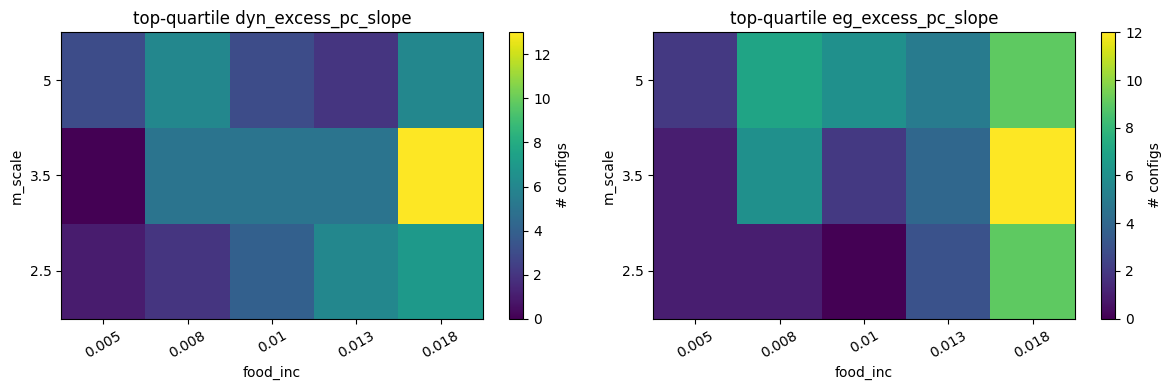

In [4]:
viable = r1[~r1.extinct].copy()
COMPOSITE = ["dyn_excess_pc_slope", "eg_excess_pc_slope", "n_distinct_genomes_temporal_std", "unique_top_genomes"]
viable["composite"] = sum((viable[c] - viable[c].mean()) / viable[c].std() for c in COMPOSITE)
top20 = viable.nlargest(20, "composite")
for p in ("param_m_scale", "param_food_inc", "param_mu_lut", "param_tax"):
    print(f"composite top-20 {p}:", top20[p].value_counts().sort_index().to_dict())
print("\nmedians over viable rows by m_scale:")
print(viable.groupby("param_m_scale")[["dyn_excess_pc_slope", "eg_excess_pc_slope", "cog_specificity_mean"]].median().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, m in zip(axes, ("dyn_excess_pc_slope", "eg_excess_pc_slope")):
    top = viable[viable[m] >= viable[m].quantile(0.75)]
    print(f"\ntop-quartile {m}: m_scale", top.param_m_scale.value_counts().sort_index().to_dict(),
          "| food_inc", top.param_food_inc.value_counts().sort_index().to_dict())
    piv = top.groupby(["param_m_scale", "param_food_inc"]).size().unstack(fill_value=0)
    im = ax.imshow(piv.values, aspect="auto", origin="lower", cmap="viridis")
    ax.set_xticks(range(len(piv.columns))); ax.set_xticklabels([f"{c:g}" for c in piv.columns], rotation=30)
    ax.set_yticks(range(len(piv.index)));   ax.set_yticklabels([f"{r:g}" for r in piv.index])
    ax.set_xlabel("food_inc"); ax.set_ylabel("m_scale"); ax.set_title(f"top-quartile {m}")
    fig.colorbar(im, ax=ax, label="# configs")
fig.tight_layout(); plt.show()

## Recorded headline (legacy rule, superseded)

R1 as recorded on 2026-05-18 (`Scans/2026-05-18_R1_mscale_bracket`) ran the legacy uncapped mouthful, under which
`m_scale × score > 25` overdrew the site (defect A9). Its headline: interior `m_scale` optimum about 2.5–3.5; `food_inc`
optimum high, 0.013–0.018, sub-0.010 closed; U-shaped viability (36% extinct); `mu_lut` optimum shifts high (top-20 mode
0.15). The cell below sets it against the rescan. Mechanism (from `Scans/2026-10-15_food_cap_impact`): legacy runs at
`m_scale` 2–3 starve under scarcity, and at 5.0 debt-fed churn depresses `eg_excess`.

In [5]:
rec = pd.read_csv(ROOT / "Research/Resource-driving/Scans/2026-05-18_R1_mscale_bracket/results.csv")
def summary(df):
    v = df[~df.extinct].copy()
    v["composite"] = sum((v[c] - v[c].mean()) / v[c].std() for c in COMPOSITE)
    t = v.nlargest(20, "composite")
    out = {"extinct": f"{int(df.extinct.sum())}/{len(df)} ({df.extinct.mean():.0%})"}
    out.update({f"extinct @ m_scale {m:g}": f"{e:.1%}" for m, e in df.groupby("param_m_scale").extinct.mean().items()})
    out.update({f"top20 {p}": t["param_" + p].value_counts().sort_index().to_dict() for p in ("m_scale", "food_inc", "mu_lut")})
    return out
pd.set_option("display.max_colwidth", 80)
display(pd.DataFrame({"recorded (legacy)": summary(rec), "rescan (standard)": summary(r1)}))

,recorded (legacy),rescan (standard)
extinct,107/300 (36%),30/300 (10%)
extinct @ m_scale 2.5,42.7%,13.5%
extinct @ m_scale 3.5,56.0%,8.3%
extinct @ m_scale 5,5.3%,8.4%
top20 m_scale,"{2.5: 10, 3.5: 8, 5.0: 2}","{2.5: 2, 3.5: 9, 5.0: 9}"
top20 food_inc,"{0.01: 2, 0.013: 8, 0.018: 10}","{0.005: 1, 0.008: 4, 0.01: 3, 0.013: 7, 0.018: 5}"
top20 mu_lut,"{0.01: 2, 0.03: 6, 0.06: 2, 0.1: 3, 0.15: 7}","{0.01: 8, 0.03: 4, 0.06: 2, 0.1: 2, 0.15: 4}"


*Sources:* `Research/Resource-driving/Scans/2026-10-23_R1_mscale_bracket_standard/` (standard rescan),
`Research/Resource-driving/Scans/2026-05-18_R1_mscale_bracket/` (recorded, legacy),
`Research/Resource-driving/Scans/2026-10-15_food_cap_impact/`, `Docs/devlog/2026-05-17_research-campaigns.md`,
research board R1 entry, `Research/Resource-driving/Resource-driving.ipynb` (R1 section and legacy section).